# 03 — Task-4 frozen-agent comparison

This notebook compares four DDQN hunt-center settings and the frozen SARSA(λ) and enhanced linear-Q baselines. The original ablation results are retained and the two additional agents use exactly the same seeds, rounds, and opponent line-ups.

**Goal:** preserve the original DDQN selection analysis while adding a fair cross-architecture Task-4 comparison.

## Protocol

Do not alter candidates or thresholds after seeing these results. The four DDQN variants share one checkpoint; `frozen_sarsa_best` and `frozen_linear_q_final` are separately frozen models. All six receive identical held-out seeds and opponent line-ups. These seeds are new relative to their training and earlier comparisons.

In [1]:
from __future__ import annotations

import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display, Markdown

def find_project_root(start=None):
    candidate = Path(start or Path.cwd()).resolve()
    for directory in (candidate, *candidate.parents):
        if (directory / 'main.py').is_file() and (directory / 'agent_code').is_dir():
            return directory
    raise FileNotFoundError('Could not find the project root containing main.py and agent_code/')

ROOT = find_project_root()
RESULT_DIR = ROOT / 'results' / 'evaluation_runs'
RESULT_DIR.mkdir(parents=True, exist_ok=True)

BASELINE = 'dueling_ddqn_agent'
CANDIDATES = [
    'dueling_hunt_center_0',
    'dueling_hunt_center_04',
    BASELINE,  # HUNT_CENTER_Q_BIAS = 0.08
    'dueling_hunt_center_12',
    'frozen_sarsa_best',
    'frozen_linear_q_final',
]
EXPECTED_CANDIDATES = {
    'dueling_hunt_center_0',
    'dueling_hunt_center_04',
    'dueling_ddqn_agent',
    'dueling_hunt_center_12',
    'frozen_sarsa_best',
    'frozen_linear_q_final',
}
assert set(CANDIDATES) == EXPECTED_CANDIDATES
missing = [a for a in CANDIDATES if not (ROOT / 'agent_code' / a).exists()]
if missing:
    raise FileNotFoundError(f'Missing ablation agent folders: {missing}')

# Fresh held-out seeds; do not use these to choose later training changes.
SEEDS = [32001, 32002, 32003, 32004, 32005]
ROUNDS_PER_SEED = 30  # 5 seeds x 30 = 150 rounds per candidate and line-up
RUN_TAG = 'task4_hunt_center_ablation_v1'

SPECS = [
    dict(label='rule_based', opponents=['rule_based_agent'] * 3),
    dict(label='mixed', opponents=['peaceful_agent', 'coin_collector_agent', 'rule_based_agent']),
]
print('Candidates:', CANDIDATES)
print(f'Planned games per candidate: {len(SEEDS) * ROUNDS_PER_SEED} per line-up')

Candidates: ['dueling_hunt_center_0', 'dueling_hunt_center_04', 'dueling_ddqn_agent', 'dueling_hunt_center_12', 'frozen_sarsa_best', 'frozen_linear_q_final']
Planned games per candidate: 150 per line-up


In [2]:
def raw_path(agent, label, seed):
    return RESULT_DIR / f'{RUN_TAG}_{agent}_{label}_seed{seed}.json'

def run_match(agent, spec, seed, force=False):
    path = raw_path(agent, spec['label'], seed)
    if path.exists() and not force:
        return path
    cmd = [sys.executable, 'main.py', 'play', '--no-gui', '--agents', agent, *spec['opponents'],
           '--scenario', 'classic', '--n-rounds', str(ROUNDS_PER_SEED), '--seed', str(seed),
           '--save-stats', str(path)]
    print('Running:', ' '.join(cmd))
    subprocess.run(cmd, cwd=ROOT, check=True)
    return path

# Set FORCE_RERUN=True only when intentionally replacing a raw result.
FORCE_RERUN = False
paths = []
for agent in CANDIDATES:
    for spec in SPECS:
        for seed in SEEDS:
            paths.append((agent, spec, seed, run_match(agent, spec, seed, force=FORCE_RERUN)))
print(f'Finished/reused {len(paths)} matches.')

Finished/reused 60 matches.


In [3]:
def candidate_totals(path, agent):
    with path.open(encoding='utf-8') as f:
        payload = json.load(f)
    matches = {name: values for name, values in payload.get('by_agent', {}).items()
               if name == agent or name.startswith(agent + '_')}
    if not matches:
        raise KeyError(f'No statistics for {agent} in {path.name}')
    totals = {}
    for values in matches.values():
        for key, value in values.items():
            if isinstance(value, (int, float)):
                totals[key] = totals.get(key, 0.0) + value
    return totals

def summarise(path, agent, label, seed):
    t = candidate_totals(path, agent)
    n, steps = t.get('rounds', 0), t.get('steps', 0)
    per_round = lambda key: t.get(key, 0.0) / n if n else np.nan
    return dict(agent=agent, lineup=label, seed=seed, rounds=n,
                mean_score=per_round('score'), coins_per_round=per_round('coins'),
                crates_per_round=per_round('crates'), bombs_per_round=per_round('bombs'),
                kills_per_round=per_round('kills'), suicides_per_round=per_round('suicides'),
                invalid_per_round=per_round('invalid'),
                mean_action_ms=1000 * t.get('time', 0.0) / steps if steps else np.nan,
                raw_file=str(path.relative_to(ROOT)))

per_seed = pd.DataFrame([summarise(path, agent, spec['label'], seed)
                             for agent, spec, seed, path in paths])
per_seed.to_csv(RESULT_DIR / f'{RUN_TAG}_per_seed.csv', index=False)
display(per_seed.sort_values(['lineup', 'agent', 'seed']).round(3))

,agent,lineup,seed,rounds,mean_score,coins_per_round,crates_per_round,bombs_per_round,kills_per_round,suicides_per_round,invalid_per_round,mean_action_ms,raw_file
25,dueling_ddqn_agent,mixed,32001,30.0,4.900,3.400,36.000,47.900,0.300,0.033,1.233,2.275,results/evaluation_runs/task4_hunt_center_abla...
26,dueling_ddqn_agent,mixed,32002,30.0,5.933,3.767,38.667,43.900,0.433,0.200,1.133,2.349,results/evaluation_runs/task4_hunt_center_abla...
27,dueling_ddqn_agent,mixed,32003,30.0,5.067,3.567,39.733,46.033,0.300,0.033,1.033,2.286,results/evaluation_runs/task4_hunt_center_abla...
28,dueling_ddqn_agent,mixed,32004,30.0,5.533,3.867,38.733,44.033,0.333,0.033,1.000,2.291,results/evaluation_runs/task4_hunt_center_abla...
29,dueling_ddqn_agent,mixed,32005,30.0,5.933,3.933,40.000,45.400,0.400,0.067,1.200,2.313,results/evaluation_runs/task4_hunt_center_abla...
5,dueling_hunt_center_0,mixed,32001,30.0,4.300,3.300,34.533,38.600,0.200,0.233,1.133,2.340,results/evaluation_runs/task4_hunt_center_abla...
6,dueling_hunt_center_0,mixed,32002,30.0,5.000,3.333,37.600,42.467,0.333,0.167,0.867,2.316,results/evaluation_runs/task4_hunt_center_abla...
7,dueling_hunt_center_0,mixed,32003,30.0,6.500,4.000,39.933,42.233,0.500,0.200,1.467,2.245,results/evaluation_runs/task4_hunt_center_abla...
8,dueling_hunt_center_0,mixed,32004,30.0,6.433,4.100,36.833,42.533,0.467,0.200,1.267,2.330,results/evaluation_runs/task4_hunt_center_abla...
9,dueling_hunt_center_0,mixed,32005,30.0,5.200,3.367,35.333,36.467,0.367,0.200,0.933,2.349,results/evaluation_runs/task4_hunt_center_abla...


,lineup,agent,mean_score_mean,mean_score_std,mean_score_count,coins_per_round_mean,coins_per_round_std,coins_per_round_count,kills_per_round_mean,kills_per_round_std,...,invalid_per_round_count,mean_action_ms_mean,mean_action_ms_std,mean_action_ms_count,mean_score_se,coins_per_round_se,kills_per_round_se,suicides_per_round_se,invalid_per_round_se,mean_action_ms_se
2,mixed,dueling_hunt_center_04,5.713,0.498,5,3.613,0.221,5,0.420,0.080,...,5,2.317,0.016,5,0.223,0.099,0.036,0.022,0.118,0.007
3,mixed,dueling_hunt_center_12,5.620,0.710,5,3.487,0.338,5,0.427,0.086,...,5,2.299,0.021,5,0.318,0.151,0.039,0.040,0.052,0.009
1,mixed,dueling_hunt_center_0,5.487,0.955,5,3.620,0.395,5,0.373,0.119,...,5,2.316,0.042,5,0.427,0.177,0.053,0.011,0.110,0.019
0,mixed,dueling_ddqn_agent,5.473,0.480,5,3.707,0.220,5,0.353,0.061,...,5,2.303,0.029,5,0.215,0.099,0.027,0.032,0.045,0.013
4,mixed,frozen_linear_q_final,3.900,0.474,5,3.100,0.264,5,0.160,0.049,...,5,9.093,0.217,5,0.212,0.118,0.022,0.043,0.019,0.097
5,mixed,frozen_sarsa_best,3.740,0.609,5,2.807,0.242,5,0.187,0.115,...,5,7.966,0.200,5,0.272,0.108,0.051,0.045,0.036,0.090
8,rule_based,dueling_hunt_center_04,4.407,0.623,5,3.040,0.390,5,0.273,0.095,...,5,2.366,0.029,5,0.279,0.175,0.043,0.012,0.101,0.013
6,rule_based,dueling_ddqn_agent,4.367,0.565,5,2.933,0.292,5,0.287,0.077,...,5,2.357,0.022,5,0.253,0.131,0.034,0.025,0.083,0.010
7,rule_based,dueling_hunt_center_0,4.233,0.462,5,2.967,0.357,5,0.253,0.038,...,5,2.366,0.046,5,0.207,0.160,0.017,0.040,0.163,0.021
9,rule_based,dueling_hunt_center_12,4.120,0.402,5,2.920,0.156,5,0.240,0.092,...,5,2.357,0.034,5,0.180,0.070,0.041,0.031,0.077,0.015


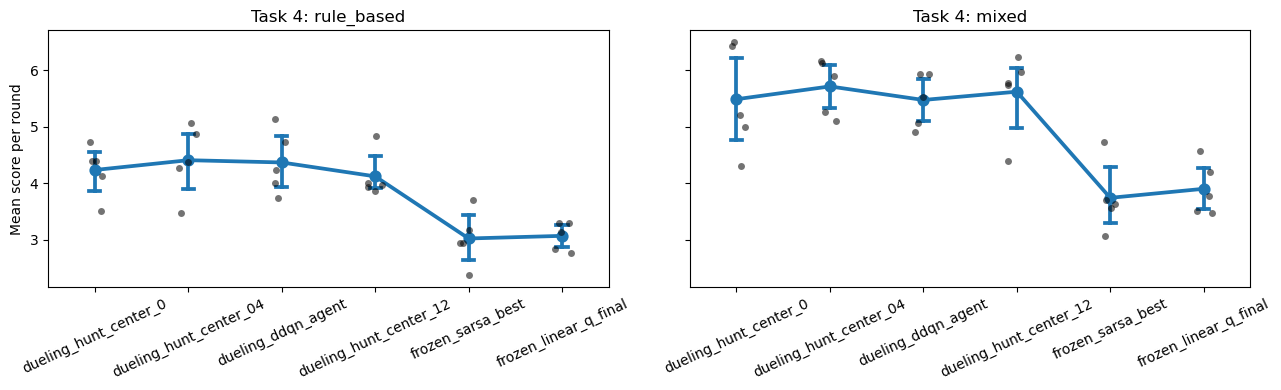

In [4]:
METRICS = ['mean_score', 'coins_per_round', 'kills_per_round', 'suicides_per_round',
           'invalid_per_round', 'mean_action_ms']
summary = (per_seed.groupby(['lineup', 'agent'])[METRICS].agg(['mean', 'std', 'count']).reset_index())
summary.columns = ['_'.join(c).rstrip('_') for c in summary.columns]
for metric in METRICS:
    summary[f'{metric}_se'] = summary[f'{metric}_std'] / np.sqrt(summary[f'{metric}_count'])
summary = summary.sort_values(['lineup', 'mean_score_mean'], ascending=[True, False])
summary.to_csv(RESULT_DIR / f'{RUN_TAG}_summary.csv', index=False)
display(summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, lineup in zip(axes, ['rule_based', 'mixed']):
    d = per_seed.query('lineup == @lineup')
    sns.pointplot(data=d, x='agent', y='mean_score', errorbar=('ci', 95), capsize=.12, ax=ax)
    sns.stripplot(data=d, x='agent', y='mean_score', color='black', alpha=.55, ax=ax)
    ax.set_title(f'Task 4: {lineup}')
    ax.set_xlabel(''); ax.tick_params(axis='x', rotation=25)
axes[0].set_ylabel('Mean score per round')
plt.tight_layout()
plt.show()

## Pre-specified selection rule

Each variant is compared with the 0.08 baseline using seed-level paired differences. A variant qualifies only if all conditions hold:

- rule-based mean score change ≥ −0.10;
- mixed mean score improves by ≥ +0.25 **or** mixed kills/round improves by ≥ +0.05;
- suicides/round do not increase in either line-up;
- invalid actions/round do not increase in either line-up.

If several variants qualify, select the one with the largest mixed score gain, using mixed kills and then rule-based score as tie-breakers. If none qualifies, retain `dueling_ddqn_agent` at 0.08.

In [5]:
key = ['lineup', 'seed']
selected = per_seed.loc[per_seed.agent.isin(CANDIDATES), key + ['agent'] + METRICS]
duplicates = selected.duplicated(key + ['agent'], keep=False)
if duplicates.any():
    duplicate_keys = selected.loc[duplicates, key + ['agent']].drop_duplicates()
    raise ValueError(f'Duplicate candidate results found:\n{duplicate_keys.to_string(index=False)}')

baseline = selected.loc[selected.agent.eq(BASELINE)].set_index(key)[METRICS]
delta_by_agent = {}
decision_rows = []
HUNT_ABLATIONS = ['dueling_hunt_center_0', 'dueling_hunt_center_04', 'dueling_hunt_center_12']
for candidate in HUNT_ABLATIONS:
    candidate_data = selected.loc[selected.agent.eq(candidate)].set_index(key)[METRICS]
    delta = candidate_data.subtract(baseline).dropna(how='any')
    lineups = set(delta.index.get_level_values('lineup')) if not delta.empty else set()
    missing_lineups = {'rule_based', 'mixed'} - lineups
    if missing_lineups:
        raise ValueError(f'{candidate} has no complete baseline pairs for {sorted(missing_lineups)}')
    delta_by_agent[candidate] = delta
    rb = delta.xs('rule_based', level='lineup').mean()
    mx = delta.xs('mixed', level='lineup').mean()
    qualifies = (
        rb.mean_score >= -0.10
        and (mx.mean_score >= 0.25 or mx.kills_per_round >= 0.05)
        and rb.suicides_per_round <= 0 and mx.suicides_per_round <= 0
        and rb.invalid_per_round <= 0 and mx.invalid_per_round <= 0
    )
    decision_rows.append({
        'agent': candidate, 'qualifies': qualifies,
        'rule_based_score_delta': rb.mean_score,
        'mixed_score_delta': mx.mean_score,
        'mixed_kills_delta': mx.kills_per_round,
        'rule_based_suicides_delta': rb.suicides_per_round,
        'mixed_suicides_delta': mx.suicides_per_round,
        'rule_based_invalid_delta': rb.invalid_per_round,
        'mixed_invalid_delta': mx.invalid_per_round,
    })

decision_table = pd.DataFrame(decision_rows).set_index('agent')
display(decision_table.round(3))
qualified = decision_table.loc[decision_table.qualifies].sort_values(
    ['mixed_score_delta', 'mixed_kills_delta', 'rule_based_score_delta'],
    ascending=False,
)
if qualified.empty:
    winner = BASELINE
    decision = 'KEEP 0.08 baseline: no ablation variant satisfies every success criterion.'
else:
    winner = qualified.index[0]
    decision = f'FREEZE {winner}: it satisfies every success criterion.'
display(Markdown(f'### Recommendation: {decision}'))

paired_summary = pd.concat(delta_by_agent, names=['candidate'])
display(paired_summary.groupby(['candidate', 'lineup']).agg(['mean', 'std', 'count']).round(3))

,qualifies,rule_based_score_delta,mixed_score_delta,mixed_kills_delta,rule_based_suicides_delta,mixed_suicides_delta,rule_based_invalid_delta,mixed_invalid_delta
agent,,,,,,,,
dueling_hunt_center_0,False,-0.133,0.013,0.020,0.033,0.127,-0.260,0.013
dueling_hunt_center_04,False,0.040,0.240,0.067,0.020,0.033,-0.047,0.133
dueling_hunt_center_12,False,-0.247,0.147,0.073,0.040,0.080,-0.047,0.080


### Recommendation: KEEP 0.08 baseline: no ablation variant satisfies every success criterion.

mean_score              coins_per_round  \
                                        mean    std count            mean   
candidate              lineup                                               
dueling_hunt_center_0  mixed           0.013  1.076     5          -0.087   
                       rule_based     -0.133  0.855     5           0.033   
dueling_hunt_center_04 mixed           0.240  0.504     5          -0.093   
                       rule_based      0.040  0.453     5           0.107   
dueling_hunt_center_12 mixed           0.147  0.437     5          -0.220   
                       rule_based     -0.247  0.791     5          -0.013   

                                               kills_per_round               \
                                     std count            mean    std count   
candidate              lineup                                                 
dueling_hunt_center_0  mixed       0.425     5           0.020  0.139     5   
                       rule_based  0.507     5          -0.033  0.097     5   
dueling_hunt_center_04 mixed       0.261     5           0.067  0.067     5   
                       rule_based  0.583     5          -0.013  0.084     5   
dueling_hunt_center_12 mixed       0.259     5           0.073  0.043     5   
                       rule_based  0.236     5          -0.047  0.117     5   

                                  suicides_per_round               \
                                                mean    std count   
candidate              lineup                                       
dueling_hunt_center_0  mixed                   0.127  0.092     5   
                       rule_based              0.033  0.103     5   
dueling_hunt_center_04 mixed                   0.033  0.053     5   
                       rule_based              0.020  0.077     5   
dueling_hunt_center_12 mixed                   0.080  0.115     5   
                       rule_based              0.040  0.095     5   

                                  invalid_per_round               \
                                               mean    std count   
candidate              lineup                                      
dueling_hunt_center_0  mixed                  0.013  0.320     5   
                       rule_based            -0.260  0.466     5   
dueling_hunt_center_04 mixed                  0.133  0.323     5   
                       rule_based            -0.047  0.150     5   
dueling_hunt_center_12 mixed                  0.080  0.069     5   
                       rule_based            -0.047  0.309     5   

                                  mean_action_ms               
                                            mean    std count  
candidate              lineup                                  
dueling_hunt_center_0  mixed               0.013  0.048     5  
                       rule_based          0.008  0.056     5  
dueling_hunt_center_04 mixed               0.014  0.035     5  
                       rule_based          0.009  0.048     5  
dueling_hunt_center_12 mixed              -0.004  0.036     5  
                       rule_based          0.000  0.046     5

## Next action

This comparison is inference-only: do not train any folder here. The original hunt-center selection rule applies only to the three DDQN ablations. SARSA and linear-Q appear in the common summary as frozen cross-architecture baselines and do not alter the previously declared DDQN decision.

## Cross-architecture conclusion

Across 150 rounds per lineup, the DDQN family remains clearly stronger in Task 4. Against rule-based opponents, `frozen_linear_q_final` scores 3.067 and `frozen_sarsa_best` 3.020, versus 4.120–4.407 for the DDQN variants. In the mixed lineup they score 3.900 and 3.740, versus 5.473–5.713.

The enhanced linear-Q baseline is slightly stronger than SARSA on score and safety in both lineups: rule-based suicides are 0.293 versus 0.333 and mixed suicides are 0.300 versus 0.327. SARSA has slightly more kills (0.100 vs 0.073 rule-based; 0.187 vs 0.160 mixed). Both linear methods have substantially fewer invalid actions than DDQN, but this does not offset their lower resource collection and kill rate.

The original DDQN ablation decision is unchanged: retain the 0.08 `dueling_ddqn_agent`, because no hunt-center variant satisfies every pre-specified success criterion.